# Program 08: simple unlearning, gradient ascent and random labels

**What:** start from program 01's model (trained on all 10 CIFAR-10 classes) and remove class 3 (cat) with two simple methods.

**How:**
- **(a) Gradient ascent (GA):** *maximize* the loss on cat images for a few steps.
- **(b) Random labels (RL):** fine-tune on cat images with random *wrong* labels, mixed with normal batches from the other 9 classes.

After every step, track **FA** (forget accuracy, on cat test images) and **RA** (retain accuracy, on the other classes).

**Why:** these are the basic tools that more advanced methods build on. Gradient ascent also shows how easily unlearning damages the rest of the model.

**Understanding note:** unlearning always pulls two ways: forget the target, but keep everything else. Pushing too hard on forgetting destroys retained knowledge.

**Done when:** you have FA and RA curves for both methods and can point to where each one starts damaging RA.

## Where this fits (for a first-time reader)

- **Program 01** trained the **original model** on all 10 classes, cats included.
- **Program 07** trained the **retrain model** without cats: the perfect target (cat accuracy 0%, other classes unchanged).
- **This program** tries to get from the original model to something *like* the retrain model **in seconds**, without retraining.

| Term | Meaning |
|---|---|
| **FA**, forget accuracy | accuracy on cat test images. Goal: as low as the retrain model (0%) |
| **RA**, retain accuracy | accuracy on the other 9 classes. Goal: stay as high as the original |
| **step** | one batch, one weight update |

A method is good if FA falls **and** RA stays put. Falling FA alone is easy: a broken model also gets 0% on cats.

## 1. Setup

In [1]:
import copy, gc, sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.data, common.models, common.train
for module in (common.utils, common.data, common.models, common.train):
    importlib.reload(module)

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from common.data import get_cifar10_unlearning_loaders
from common.models import resnet18_cifar
from common.utils import RESULTS_DIR, get_device, log_run, set_seed

SETTINGS = {
    "forget_class": 3,        # cat
    "batch_size": 128, "seed": 0,
    "workers": 0,             # 0 = load images in the main process. Only 150 small steps per method, so this is
                              # fast enough, and it saves ~2 GB of RAM (each worker process costs ~0.5 GB)
    # (a) gradient ascent
    "ga_lr": 1e-3, "ga_steps": 150,
    # (b) random labels
    "rl_lr": 1e-3, "rl_steps": 150,   # 1e-2 wrecks RA within one step: program 01 ended training at lr ~0
    # measuring
    "ra_eval_images": 2000,   # retain test images checked after every step (all 9,000 at the end)
    "forget_target": 0.01,    # "forgotten" = FA at or below 1%
    "damage_points": 2.0,     # "RA damaged" = RA more than 2 points below the original
}
device = get_device()
print("device:", device)

device: cuda


## 2. Data, the original model, and the target

We load:
- the forget / retain loaders (same split as program 07),
- **program 01's model**, the one we will unlearn from. If the file is missing, run program 01 first.
- program 07's **reference** (what the retrain model does with cat images), if it exists, to compare at the end.

**Memory (8 GB laptop).** Measuring needs no data-loading processes: all 10,000 test images are loaded **once** into GPU memory as one tensor (about 120 MB of the GPU's 4 GB), and every check just runs the model on slices of it. That is also much faster than going through a loader after every step.

After every unlearning step we check all 1,000 cat test images and a fixed random sample of 2,000 of the other test images. The final numbers (section 7) use all 10,000.

`full_eval` measures one model and returns **numbers only** (FA, RA, confidence on cats, where cat images go). Section 7 compares those numbers, so we never need two unlearned models in memory at once.

In [2]:
loaders = get_cifar10_unlearning_loaders(SETTINGS["forget_class"], SETTINGS["batch_size"], SETTINGS["workers"])
classes = loaders["classes"]
FORGET = SETTINGS["forget_class"]

# All test images, loaded once into GPU memory.
test_set = loaders["test_all"].dataset
xs, ys = zip(*(test_set[i] for i in range(len(test_set))))
X_test, Y_test = torch.stack(xs).to(device), torch.tensor(ys, device=device)
del xs, ys
gc.collect()
cat_mask = Y_test == FORGET

# Per-step check sets: all cat test images + a fixed sample of the others.
rng = np.random.RandomState(SETTINGS["seed"])
retain_idx = torch.where(~cat_mask)[0].cpu().numpy()
pick = torch.from_numpy(rng.choice(retain_idx, SETTINGS["ra_eval_images"], replace=False)).to(device)
X_fa = X_test[cat_mask]
X_ra, Y_ra = X_test[pick], Y_test[pick]


@torch.no_grad()
def logits_of(model, X, chunk=1000):
    model.eval()
    return torch.cat([model(X[i:i + chunk]) for i in range(0, len(X), chunk)])


def quick_eval(model):
    """(FA, RA) on the per-step check sets."""
    fa = (logits_of(model, X_fa).argmax(1) == FORGET).float().mean().item()
    ra = (logits_of(model, X_ra).argmax(1) == Y_ra).float().mean().item()
    return fa, ra


def full_eval(model):
    """Numbers only, on all 10,000 test images: FA, RA, confidence on cats, where cat images go."""
    out = logits_of(model, X_test).float()
    pred = out.argmax(1)
    acc = np.array([(pred[Y_test == c] == c).float().mean().item() for c in range(10)])
    probs_cat = torch.softmax(out[cat_mask], dim=1)
    share = torch.bincount(probs_cat.argmax(1), minlength=10).float() / len(probs_cat)
    return {"fa": float(acc[FORGET]), "ra": float(np.delete(acc, FORGET).mean()),
            "cat_conf": probs_cat.max(1).values.mean().item(), "pred_share": share.cpu().numpy()}


results = {}   # model name -> numbers from full_eval

original_path = RESULTS_DIR / "01_resnet18_cifar10.pt"
if not original_path.exists():
    raise FileNotFoundError(f"{original_path} not found. Run program 01 first: it saves the model we unlearn from.")
original = resnet18_cifar(num_classes=10).to(device)
original.load_state_dict(torch.load(original_path, map_location=device))

fa0, ra0 = quick_eval(original)
results["original (01)"] = full_eval(original)
print(f"original model: FA {results['original (01)']['fa']*100:.1f}%  RA {results['original (01)']['ra']*100:.1f}%  "
      f"(per-step check sets: FA {fa0*100:.1f}%  RA {ra0*100:.1f}%)")

ref_path = RESULTS_DIR / "07_retrain_reference.npz"
retrain_ref = np.load(ref_path) if ref_path.exists() else None
if retrain_ref is not None:
    ra_retrain = np.delete(retrain_ref["per_class_acc"], FORGET).mean()
    print(f"retrain model (program 07): FA {retrain_ref['per_class_acc'][FORGET]*100:.1f}%  RA {ra_retrain*100:.1f}%")
else:
    print("program 07 reference not found: the comparison with the retrain model will be skipped.")

original model: FA 85.7%  RA 94.5%  (per-step check sets: FA 85.7%  RA 95.1%)
retrain model (program 07): FA 0.0%  RA 94.9%


## 3. Shared pieces for both methods

- `forever(loader)`: hand out batches endlessly, reshuffling each pass, so a method can run any number of steps.
- **BatchNorm is frozen** (`model.eval()` while updating). Unlearning batches are unusual (all cats, or half cats with wrong labels). If BatchNorm kept updating its running mean and variance on them, it would damage RA for reasons unrelated to the method itself. Freezing it means only the weights change, so the curves show the method's effect alone. Gradients still flow normally in eval mode.
- No mixed precision here: gradient ascent drives the loss up without limit, which can overflow float16.
- `run_unlearning` runs a method step by step on a copy of the original model and checks FA and RA after each step. At the first step where it counts as forgotten (FA ≤ 1%) it saves a copy of the weights **in normal RAM** (about 45 MB): that is the model you would ship if you stopped as soon as the cat was gone.
- When the method finishes, it measures the final model and the saved "forgotten" weights with `full_eval`, keeps only the numbers, and **deletes both** before returning. So only the original model and one working copy are ever in GPU memory.

In [3]:
def forever(loader):
    while True:
        for batch in loader:
            yield batch


def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()


def run_unlearning(name, step_fn, lr, n_steps):
    """Unlearn a copy of the original model; record FA/RA after each step; measure and delete at the end."""
    set_seed(SETTINGS["seed"])
    model = copy.deepcopy(original)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    hist = {"step": [0], "fa": [fa0], "ra": [ra0], "forget_loss": [np.nan]}
    forgot_weights, forgot_step = None, None
    start = time.time()

    for step in range(1, n_steps + 1):
        model.eval()                                   # BatchNorm frozen, see above
        forget_loss = step_fn(model, optimizer)
        if not np.isfinite(forget_loss):
            print(f"{name}: loss became {forget_loss} at step {step}, stopping.")
            break
        fa, ra = quick_eval(model)
        for k, v in zip(hist, [step, fa, ra, forget_loss]):
            hist[k].append(v)
        if forgot_weights is None and fa <= SETTINGS["forget_target"]:
            forgot_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            forgot_step = step
        if step % 10 == 0 or step == 1:
            print(f"{name} step {step:3d}: FA {fa*100:5.1f}%  RA {ra*100:5.1f}%  "
                  f"cat CE {forget_loss:7.3f}  ({time.time()-start:.0f}s)")
    hist["seconds"] = time.time() - start

    # Measure, keep the numbers, delete the models.
    results[f"{name} @ end"] = full_eval(model)
    if forgot_weights is not None:
        model.load_state_dict(forgot_weights)
        results[f"{name} @ step {forgot_step}"] = full_eval(model)
    del model, optimizer, forgot_weights
    free_gpu()
    return hist, forgot_step

## 4. Method (a): gradient ascent

Normal training does **gradient descent**: move the weights to make the loss on the training data *smaller*. Gradient ascent does the opposite on the forget data: move the weights to make the loss on cat images **larger**.

$$\theta \leftarrow \theta + \eta \, \nabla_\theta \, \text{CE}(f_\theta(x_{cat}), \text{cat})$$

In code that is simply `loss = -CE` followed by the usual descent step.

**What to expect.** The cat loss rises and FA falls fast. But nothing in this loss mentions the other 9 classes. Cross-entropy can grow without limit, so after the cat is gone the method keeps pushing, and the easiest way to keep increasing the loss is to break the shared features. Watch for the step where RA starts to fall: that is the damage the understanding note warns about.

In [4]:
forget_iter = forever(loaders["train_forget"])

def ga_step(model, optimizer):
    x, y = next(forget_iter)
    x, y = x.to(device), y.to(device)
    ce = F.cross_entropy(model(x), y)
    optimizer.zero_grad(set_to_none=True)
    (-ce).backward()                 # ascent: minimize the NEGATIVE loss
    optimizer.step()
    return ce.item()

ga_hist, ga_forgot_step = run_unlearning("GA", ga_step, SETTINGS["ga_lr"], SETTINGS["ga_steps"])
print(f"\nGA: forgotten (FA <= {SETTINGS['forget_target']*100:.0f}%) at step {ga_forgot_step}, {ga_hist['seconds']:.0f}s in total")

GA step   1: FA  84.4%  RA  95.1%  cat CE   0.048  (1s)
GA step  10: FA   0.0%  RA  12.2%  cat CE  35.615  (10s)
GA: loss became nan at step 13, stopping.

GA: forgotten (FA <= 1%) at step 7, 12s in total


## 5. Method (b): random labels

Instead of "make the cat loss big", random labels say "learn something **else** for these images":
- **Forget half of each step:** cat images with a random *wrong* label (one of the other 9 classes, chosen fresh each time).
- **Retain half:** normal images of the other 9 classes with their true labels.

Both halves go through one forward pass, and the loss is the usual cross-entropy over all of them. The loss is bounded (it is normal training, just on odd labels), and the retain half actively keeps the other classes working. So we expect RA to hold up much better than with gradient ascent.

**A cost to notice.** The cat images are taught to look like *random* classes. The retrain model (program 07) doesn't do that: it mostly calls cats "dog". Section 7 checks whether this leaves a different fingerprint from the true target.

In [5]:
forget_iter = forever(loaders["train_forget"])
retain_iter = forever(loaders["train_retain"])

def rl_step(model, optimizer):
    xf, yf = next(forget_iter)
    xr, yr = next(retain_iter)
    wrong = (yf + torch.randint(1, 10, yf.shape)) % 10      # any class except the true one
    x = torch.cat([xf, xr]).to(device)
    y = torch.cat([wrong, yr]).to(device)
    out = model(x)
    loss = F.cross_entropy(out, y)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    with torch.no_grad():                                   # cat CE w.r.t. the TRUE label, to compare with GA
        cat_ce = F.cross_entropy(out[: len(yf)], yf.to(device)).item()
    return cat_ce

rl_hist, rl_forgot_step = run_unlearning("RL", rl_step, SETTINGS["rl_lr"], SETTINGS["rl_steps"])
print(f"\nRL: forgotten (FA <= {SETTINGS['forget_target']*100:.0f}%) at step {rl_forgot_step}, {rl_hist['seconds']:.0f}s in total")

# Both methods are done: free the training loaders' worker processes and the original model.
del forget_iter, retain_iter, original
loaders["train_forget"] = loaders["train_retain"] = None
free_gpu()

RL step   1: FA  70.4%  RA  95.4%  cat CE   0.048  (1s)
RL step  10: FA   0.0%  RA  75.4%  cat CE   4.935  (11s)
RL step  20: FA   0.0%  RA  86.9%  cat CE   5.828  (21s)
RL step  30: FA   0.0%  RA  88.9%  cat CE   6.021  (32s)
RL step  40: FA   0.0%  RA  90.6%  cat CE   5.574  (43s)
RL step  50: FA   0.0%  RA  92.0%  cat CE   5.527  (53s)
RL step  60: FA   0.0%  RA  93.0%  cat CE   5.422  (64s)
RL step  70: FA   0.0%  RA  94.0%  cat CE   5.410  (74s)
RL step  80: FA   0.0%  RA  94.2%  cat CE   5.229  (85s)
RL step  90: FA   0.0%  RA  94.5%  cat CE   5.378  (96s)
RL step 100: FA   0.0%  RA  94.4%  cat CE   5.234  (106s)
RL step 110: FA   0.0%  RA  94.4%  cat CE   5.392  (117s)
RL step 120: FA   0.0%  RA  94.9%  cat CE   4.944  (127s)
RL step 130: FA   0.0%  RA  94.7%  cat CE   5.229  (138s)
RL step 140: FA   0.0%  RA  95.0%  cat CE   5.273  (149s)
RL step 150: FA   0.0%  RA  94.9%  cat CE   5.158  (159s)

RL: forgotten (FA <= 1%) at step 4, 159s in total


## 6. The curves: where does each method start damaging RA?

This is the "Done when" plot. For each method:
- **FA** and **RA** after every step.
- A dotted line at the step where it first counts as **forgotten** (FA ≤ 1%).
- A dashed line at the step where **RA is first damaged** (more than 2 points below the original).

If the dashed line comes *before* the dotted one, the method breaks the model before it has even finished forgetting.

GA: forgotten at step 7,  RA damaged from step 7
RL: forgotten at step 4,  RA damaged from step 3


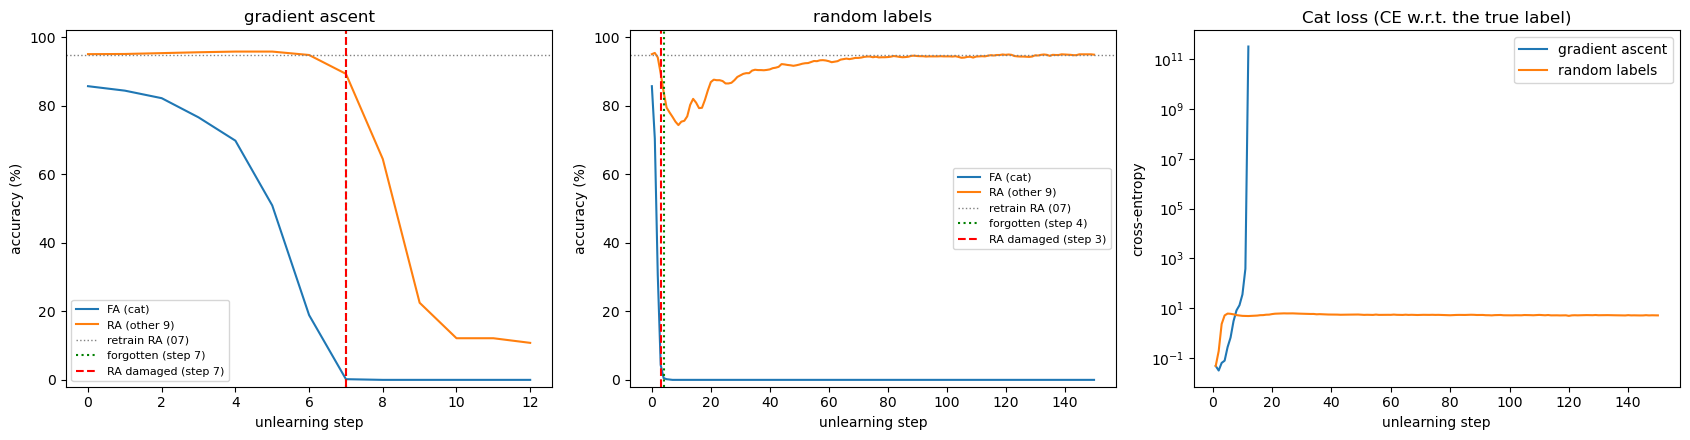

In [6]:
def first_step(hist, cond):
    for s, fa, ra in zip(hist["step"], hist["fa"], hist["ra"]):
        if cond(fa, ra):
            return s
    return None

damage = SETTINGS["damage_points"] / 100
marks = {}
for name, hist in [("GA", ga_hist), ("RL", rl_hist)]:
    marks[name] = {"forgot": first_step(hist, lambda fa, ra: fa <= SETTINGS["forget_target"]),
                   "damage": first_step(hist, lambda fa, ra: ra < ra0 - damage)}
    print(f"{name}: forgotten at step {marks[name]['forgot']},  RA damaged from step {marks[name]['damage']}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (name, hist) in zip(axes[:2], [("gradient ascent", ga_hist), ("random labels", rl_hist)]):
    key = "GA" if name.startswith("gradient") else "RL"
    ax.plot(hist["step"], np.array(hist["fa"]) * 100, label="FA (cat)")
    ax.plot(hist["step"], np.array(hist["ra"]) * 100, label="RA (other 9)")
    if retrain_ref is not None:
        ax.axhline(ra_retrain * 100, color="gray", ls=":", lw=1, label="retrain RA (07)")
    if marks[key]["forgot"] is not None:
        ax.axvline(marks[key]["forgot"], color="green", ls=":", label=f"forgotten (step {marks[key]['forgot']})")
    if marks[key]["damage"] is not None:
        ax.axvline(marks[key]["damage"], color="red", ls="--", label=f"RA damaged (step {marks[key]['damage']})")
    ax.set(title=name, xlabel="unlearning step", ylabel="accuracy (%)", ylim=(-2, 102))
    ax.legend(fontsize=8)

axes[2].plot(ga_hist["step"], ga_hist["forget_loss"], label="gradient ascent")
axes[2].plot(rl_hist["step"], rl_hist["forget_loss"], label="random labels")
axes[2].set(title="Cat loss (CE w.r.t. the true label)", xlabel="unlearning step", ylabel="cross-entropy", yscale="log")
axes[2].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "08_fa_ra_curves.png", dpi=120)
plt.show()

## 7. Compare with the retrain model, on the full test set

Each method gave two models: the one at the **forgotten** step (stop as soon as the cat is gone) and the one at the **end** (kept going). They were already measured on all 10,000 test images and deleted; here we compare their saved numbers with the original and the retrain model:
- **FA, RA**: the two headline numbers.
- **Where cat images go**: the retrain model mostly answers "dog". A method that sends cats somewhere very different leaves a fingerprint: someone could tell it was unlearned, not retrained.
- **Confidence on cat images**: program 10 uses differences like this to detect leftover memory.

             model      FA      RA  cat conf  most common answer for cats
     original (01)   85.7%   94.5%     91.8%  cat (86%)
          GA @ end    0.0%   11.1%      nan%  airplane (100%)
       GA @ step 7    0.2%   88.1%     76.8%  dog (58%)
          RL @ end    0.0%   94.4%     29.1%  dog (26%)
       RL @ step 4    0.5%   83.3%     61.3%  ship (20%)
      retrain (07)    0.0%   94.9%     83.6%  dog (58%)


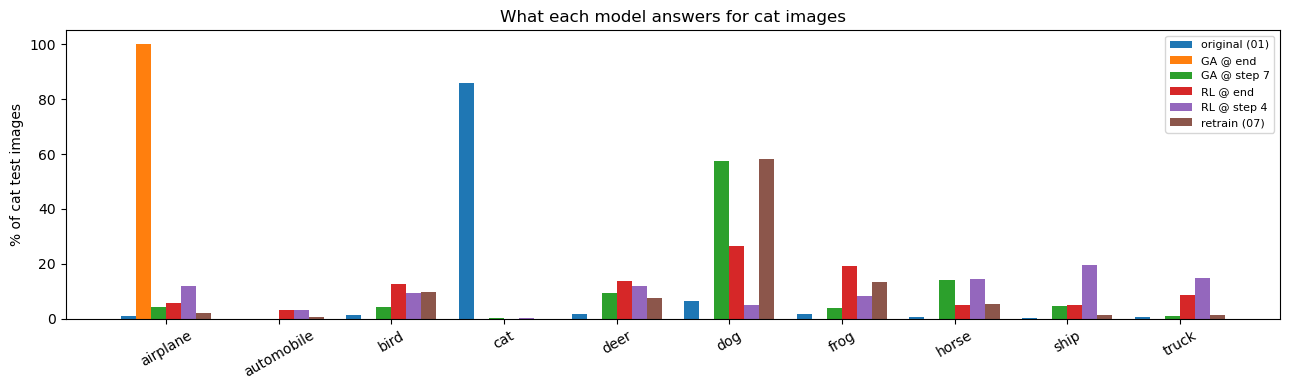

In [7]:
print(f"{'model':>18} {'FA':>7} {'RA':>7} {'cat conf':>9}  most common answer for cats")
for name, r in results.items():
    top = r["pred_share"].argmax()
    print(f"{name:>18} {r['fa']*100:6.1f}% {r['ra']*100:6.1f}% {r['cat_conf']*100:8.1f}%  "
          f"{classes[top]} ({r['pred_share'][top]*100:.0f}%)")

pred_shares = {name: r["pred_share"] for name, r in results.items()}
if retrain_ref is not None:
    share = retrain_ref["forget_pred_share"]
    pred_shares["retrain (07)"] = share
    print(f"{'retrain (07)':>18} {retrain_ref['per_class_acc'][FORGET]*100:6.1f}% {ra_retrain*100:6.1f}% "
          f"{retrain_ref['forget_conf'].mean()*100:8.1f}%  {classes[share.argmax()]} ({share.max()*100:.0f}%)")

names = list(pred_shares)
x = np.arange(10)
width = 0.8 / len(names)
plt.figure(figsize=(13, 4))
for i, name in enumerate(names):
    plt.bar(x + (i - len(names) / 2 + 0.5) * width, pred_shares[name] * 100, width, label=name)
plt.xticks(x, classes, rotation=30)
plt.ylabel("% of cat test images")
plt.title("What each model answers for cat images")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "08_cat_predictions.png", dpi=120)
plt.show()

## 8. Optional: change the step size

The learning rate decides how fast each method forgets and how fast it breaks things.
- Gradient ascent: try `ga_lr` 1e-4 (slower, gentler) and 1e-2 (faster, more destructive).
- Random labels: try `rl_lr` 1e-2. In a short test this dropped RA from 95% to 26% within 3 steps: program 01's model finished training at a learning rate near 0, so a sudden large step wrecks it. A good reminder that "how hard you push" matters as much as the method.

Change them in section 1 and run again from the top (each run takes a few minutes). Each run is logged. A question to answer: is there an `ga_lr` where gradient ascent forgets **without** damaging RA, or does it always break the model before or right after FA reaches 0?

## 9. Log the run

In [8]:
log_run("08_simple_unlearn", SETTINGS,
        {"original": {"fa": fa0, "ra_subset": ra0},
         "ga": {"forgot_step": ga_forgot_step, "damage_step": marks["GA"]["damage"], "seconds": round(ga_hist["seconds"], 1)},
         "rl": {"forgot_step": rl_forgot_step, "damage_step": marks["RL"]["damage"], "seconds": round(rl_hist["seconds"], 1)},
         "full_test": {name: {k: (v.round(4).tolist() if isinstance(v, np.ndarray) else round(v, 4))
                              for k, v in r.items()} for name, r in results.items()}})
np.savez(RESULTS_DIR / "08_curves.npz",
         ga_fa=ga_hist["fa"], ga_ra=ga_hist["ra"], rl_fa=rl_hist["fa"], rl_ra=rl_hist["ra"])
print("logged to", RESULTS_DIR / "runs.jsonl")

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. For each method: at which step was the cat forgotten, and at which step did RA start to fall? Which came first?
2. Gradient ascent's cat loss grows without limit. Why does that eventually destroy the other classes, even though their data is never used?
3. Random labels kept RA much better (check this). Which part of the method is responsible: the wrong labels or the retain half?
4. Compare where each model sends cat images with the retrain model (mostly dog?). Which method looks more like true forgetting from the outside?
5. Both methods took seconds; program 07 took minutes. Is the speed worth the differences you see in section 7?